LIBRERIAS

In [1]:
# Manipulacion de datos
import pandas as pd
import numpy as np
from datetime import datetime

# Visualizacion
import matplotlib.pyplot as plt

# Machine Learning
import sklearn

# Metricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Ignorar warnings
import warnings
warnings.filterwarnings("ignore")

ARCHIVOS UTILIZADOS

In [2]:
solicitudes_train = pd.read_csv("solicitudes_train.csv")
comportamiento_bancario = pd.read_csv("comportamiento_bancario.csv")
solicitudes_test = pd.read_csv("solicitudes_test.csv")

ANALISIS DE CANTIDAD DE REGISTROS DE LOS DATASET

In [3]:
print("TRAIN:", solicitudes_train.shape)
print("BANCO:", comportamiento_bancario.shape)
print("TEST:", solicitudes_test.shape)

TRAIN: (32416, 8)
BANCO: (661139, 4)
TEST: (3061, 7)


INFORMACION ACERCA DEL DATASET DE COMPORTAMIENTO BANCARIO

In [4]:
comportamiento_bancario.info()
comportamiento_bancario.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 661139 entries, 0 to 661138
Data columns (total 4 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID_Usuario                661139 non-null  int64  
 1   Mes_Referencia            661139 non-null  object 
 2   Saldo_Promedio_Mensual    661139 non-null  float64
 3   Dias_Atraso_Otras_Deudas  661139 non-null  int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 20.2+ MB


,ID_Usuario,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
0,1,2024-01,12768.11,3
1,1,2024-02,15817.67,3
2,1,2024-03,13138.66,0
3,1,2024-04,19453.13,0
4,1,2024-05,14943.44,59


INFORMACION ACERCA DEL DATASET DE SOLICITUDES TRAIN

In [5]:
solicitudes_train.info()
solicitudes_train.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32416 entries, 0 to 32415
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Solicitud      32416 non-null  int64  
 1   ID_Usuario        32416 non-null  int64  
 2   Monto_Solicitado  32416 non-null  int64  
 3   Tasa_Interes      32416 non-null  float64
 4   Ingreso_Mensual   32416 non-null  int64  
 5   Motivo_Prestamo   32416 non-null  object 
 6   Fecha_Solicitud   32416 non-null  object 
 7   Estado_Final      32416 non-null  int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 2.0+ MB


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final
0,1,12698,7900,0.2333,4461,Consumo,2025-04,1
1,2,20744,17400,0.2507,3889,Vivienda,2025-12,1
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06,0
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07,1
4,5,24719,6600,0.2314,3357,Otros,2025-01,1


CON ESTE ANALISIS SE PUDO OBSERVAR QUE NO SE ENCUENTRAN REGISTROS NULOS EN NINGUNO DE LOS DOS DATASETS Y QUE LA MAYORIA DE VARIABLES SON NUMERICAS OBVIANDO LAS FECHAS Y LA CATEGORIA (MOTIVO) DEL PRESTAMO

---
ANALISIS DE INFLUENCIA DEL MONTO SOLICITADO EN EL PRESTAMO SOBRE SI FUE PAGO O NO:

In [6]:
solicitudes_train.groupby("Estado_Final")[["Monto_Solicitado"]].describe()

Monto_Solicitado                                             \
                        count          mean           std    min     25%   
Estado_Final                                                               
0                      5171.0  17280.970799  15223.807373  500.0  6800.0   
1                     27245.0  13722.440815  12447.088897  500.0  5500.0   

                                         
                  50%      75%      max  
Estado_Final                             
0             12400.0  22500.0  70000.0  
1              9800.0  17400.0  70000.0

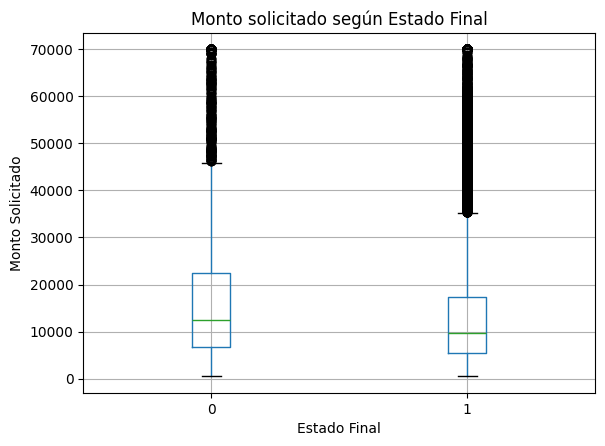

In [7]:
import matplotlib.pyplot as plt

solicitudes_train.boxplot(column="Monto_Solicitado", by="Estado_Final")

plt.xlabel("Estado Final")
plt.ylabel("Monto Solicitado")
plt.title("Monto solicitado según Estado Final")
plt.suptitle("")
plt.show()

SE PUEDE OBSERVAR UNA LEVE INFLUENCIA EN LOS MONTOS SUPERIORES A 12000, PERO NO ES LO SUFICIENTEMENTE GRANDE LA DIFERENCIA COMO PARA TOMARLO COMO UN PATRON O CONEXION.

---

ANALISIS DE LAS VARIABLES SALDO PROMEDIO Y DIAS ATRASO EN COMPORTAMIENTO BANCARIO

In [8]:
comportamiento_bancario[["Saldo_Promedio_Mensual","Dias_Atraso_Otras_Deudas"]].describe()

,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
count,661139.000000,661139.000000
mean,5463.296614,8.950755
std,5473.861364,13.199638
min,3.300000,0.000000
25%,2061.955000,1.000000
50%,3974.280000,5.000000
75%,7082.925000,10.000000
max,165915.350000,90.000000


NO PARECE HABER RELACION ENTRE EL SALDO PROMEDIO Y LOS DIAS DE ATRASO

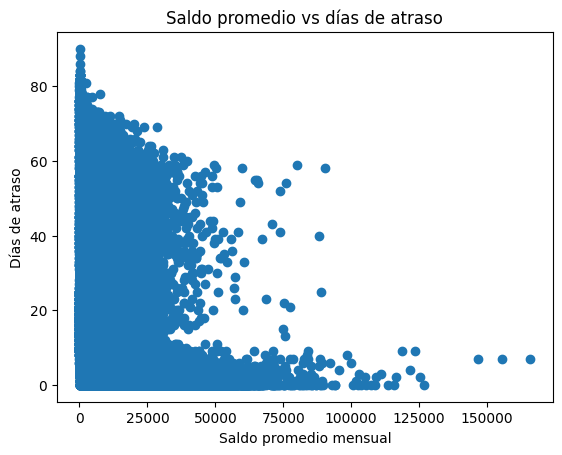

In [9]:
plt.scatter(comportamiento_bancario["Saldo_Promedio_Mensual"], comportamiento_bancario["Dias_Atraso_Otras_Deudas"])

plt.xlabel("Saldo promedio mensual")
plt.ylabel("Días de atraso")
plt.title("Saldo promedio vs días de atraso")
plt.show()

ANALISIS DE RANGOS DE LAS FECHAS EN AMBOS DATASET


HAY QUE TENER CUIDADO CON DATA LEAKEAGE DE FECHAS AL MEZCLAR REGISTROS

In [10]:
# CUIDADO CON DATA LEAKEAGE DE FECHAS AL MEZCLAR REGISTROS

print(solicitudes_train["Fecha_Solicitud"].dtype)
print(comportamiento_bancario["Mes_Referencia"].dtype)

print(solicitudes_train["Fecha_Solicitud"].min())
print(solicitudes_train["Fecha_Solicitud"].max())

print(comportamiento_bancario["Mes_Referencia"].min())
print(comportamiento_bancario["Mes_Referencia"].max())

object
object
2025-01
2025-12
2024-01
2025-12


In [ ]:
# COLUMNAS DE INTERES: SALDO PROMEDIO MENSUAL Y MONTO SOLICITADO CON RESPECTO A ESTADO_FINAL
# JUNTAR MONTO, ESTADO_FINAL CON PROM DE SALDO, PROM ATRASOS HISTORICOS DESDE LA FECHA DE SOLICITUD HACIA ATRAS (NO ADELANTE POR LEAKEAGE)

UNIFICAMOS LOS DATASETS PARA PODER SEGUIR BUSCANDO RELACIONES ENTRE COLUMNAS

In [11]:
# UNIFICACION DE DATOS PARA DATASET_FINAL_TRAIN
solicitudes_train["Fecha_Solicitud"] = pd.to_datetime(solicitudes_train["Fecha_Solicitud"])
comportamiento_bancario["Mes_Referencia"] = pd.to_datetime(comportamiento_bancario["Mes_Referencia"])

# UNIFICACION Y AGREGACION DE HISTORICO
datos_combinados_train = solicitudes_train.merge(comportamiento_bancario, on="ID_Usuario", how="left")

# Filtro anti-leakage (solo comportamiento estricto antes de la solicitud)
datos_combinados_train = datos_combinados_train[datos_combinados_train["Mes_Referencia"] < datos_combinados_train["Fecha_Solicitud"]]

# Agregación múltiple directa con nombres claros
historico_train = (
    datos_combinados_train.groupby("ID_Solicitud").agg(
        # Saldos
        Saldo_Historico_Promedio=("Saldo_Promedio_Mensual", "mean"),
        # Días de atraso
        Atrasos_Historicos_Promedio=("Dias_Atraso_Otras_Deudas", "mean"),
        Atrasos_Historicos_Max=("Dias_Atraso_Otras_Deudas", "max"),
        # Antigüedad en meses observados
        Meses_Historial_Cuenta=("Mes_Referencia", "count"),
    ).reset_index()
)

# Merge final con el dataset de solicitudes
datos_final_train = solicitudes_train.merge(historico_train, on="ID_Solicitud", how="left")
datos_final_train["Mes_Solicitud"] = datos_final_train["Fecha_Solicitud"].dt.month
datos_final_train.columns

Index(['ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes',
       'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 'Estado_Final',
       'Saldo_Historico_Promedio', 'Atrasos_Historicos_Promedio',
       'Atrasos_Historicos_Max', 'Meses_Historial_Cuenta', 'Mes_Solicitud'],
      dtype='object')

In [12]:
datos_final_train.isnull().sum()

,0
ID_Solicitud,0
ID_Usuario,0
Monto_Solicitado,0
Tasa_Interes,0
Ingreso_Mensual,0
Motivo_Prestamo,0
Fecha_Solicitud,0
Estado_Final,0
Saldo_Historico_Promedio,0
Atrasos_Historicos_Promedio,0


In [ ]:
datos_final_train["ID_Solicitud"].duplicated().sum()

0

In [13]:
datos_final_train[
    [
        "ID_Usuario",
        "ID_Solicitud",
        "Fecha_Solicitud",
        "Monto_Solicitado",
        "Saldo_Historico_Promedio",
        "Atrasos_Historicos_Promedio",
        "Atrasos_Historicos_Max",
        "Meses_Historial_Cuenta",
        "Mes_Solicitud",
        "Estado_Final"
    ]
].sample(10)

,ID_Usuario,ID_Solicitud,Fecha_Solicitud,Monto_Solicitado,Saldo_Historico_Promedio,Atrasos_Historicos_Promedio,Atrasos_Historicos_Max,Meses_Historial_Cuenta,Mes_Solicitud,Estado_Final
27690,23681,27691,2025-05-01,15000,11592.432667,13.333333,56,15,5,1
2047,1529,2048,2025-02-01,13700,55.715455,30.545455,65,11,2,0
9010,8684,9011,2025-11-01,8400,4626.606190,5.809524,43,21,11,1
7214,21564,7215,2025-06-01,22300,24496.591176,2.529412,30,17,6,1
11031,22750,11032,2025-12-01,3400,1794.509091,3.318182,18,22,12,1
15053,14501,15054,2025-01-01,8600,2586.325833,17.500000,44,12,1,1
17413,13791,17414,2025-05-01,4100,404.690625,24.687500,68,16,5,1
9074,13923,9075,2025-03-01,8400,8271.465714,3.785714,7,14,3,1
50,15650,51,2025-03-01,19800,6828.302727,17.181818,45,11,3,0
1704,21358,1705,2025-01-01,14900,10969.468333,7.250000,49,12,1,1


In [14]:
datos_final_train[
    datos_final_train["ID_Usuario"] == 12691
][
    [
        "ID_Usuario",
        "ID_Solicitud",
        "Fecha_Solicitud",
        "Monto_Solicitado",
        "Saldo_Historico_Promedio",
        "Atrasos_Historicos_Promedio",
        "Atrasos_Historicos_Max",
        "Meses_Historial_Cuenta",
        "Mes_Solicitud",
        "Estado_Final"
    ]
]

,ID_Usuario,ID_Solicitud,Fecha_Solicitud,Monto_Solicitado,Saldo_Historico_Promedio,Atrasos_Historicos_Promedio,Atrasos_Historicos_Max,Meses_Historial_Cuenta,Mes_Solicitud,Estado_Final
13408,12691,13409,2025-10-01,29800,2000.049048,8.0,46,21,10,1
17735,12691,17736,2025-03-01,12400,2248.863571,7.0,46,14,3,1


In [15]:
datos_final_train.groupby("Estado_Final")[
    [
        "Saldo_Historico_Promedio",
        "Atrasos_Historicos_Promedio"
    ]
].describe()

Saldo_Historico_Promedio                                       \
                                count         mean          std        min   
Estado_Final                                                                 
0                              5171.0  2683.907584  2891.777211  23.043043   
1                             27245.0  5801.107374  4804.676139  25.440556   

                                                                   \
                      25%          50%          75%           max   
Estado_Final                                                        
0              631.139063  1909.930714  3776.945833  35092.751429   
1             2591.194545  4549.311176  7550.470000  53201.797692   

             Atrasos_Historicos_Promedio                                 \
                                   count       mean       std       min   
Estado_Final                                                              
0                                 5171.0  15.905872  7.847707  0.272727   
1                                27245.0   7.657974  5.650891  0.000000   

                                                         
                    25%        50%       75%        max  
Estado_Final                                             
0             10.133333  15.400000  20.94281  52.272727  
1              3.428571   6.318182  10.70000  49.083333

**ANALISIS DEL SALDO PROMEDIO HISTORICO SOBRE EL ESTADO FINAL DEL PRESTAMO**

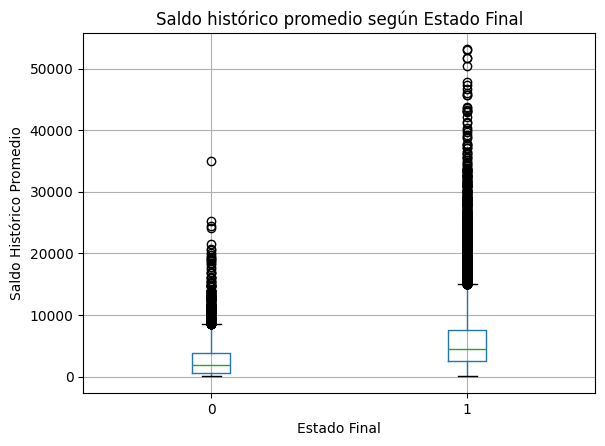

In [16]:
datos_final_train.boxplot(column="Saldo_Historico_Promedio", by="Estado_Final")

plt.xlabel("Estado Final")
plt.ylabel("Saldo Histórico Promedio")
plt.title("Saldo histórico promedio según Estado Final")
plt.suptitle("")
plt.show()

**SE PUEDE OBSERVAR UN INDICIO DE RELACION ENTRE SALDOS BAJOS Y PRESTAMOS NO PAGOS.**

---
**ANALISIS DE ATRASOS PROMEDIOS HISTORICOS SOBRE EL ESTADO FINAL DEL PRESTAMO.**

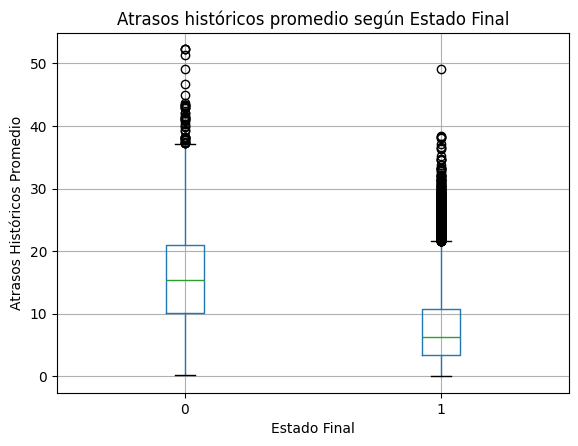

In [17]:
datos_final_train.boxplot(column="Atrasos_Historicos_Promedio", by="Estado_Final")

plt.xlabel("Estado Final")
plt.ylabel("Atrasos Históricos Promedio")
plt.title("Atrasos históricos promedio según Estado Final")
plt.suptitle("")
plt.show()

SE OBSERVA UNA BUENA RELACION DE LAS VARIABLES ENTRE SI

---
ANALISIS DE LA MATRIZ DE CORRELACION DE LAS VARIABLES.

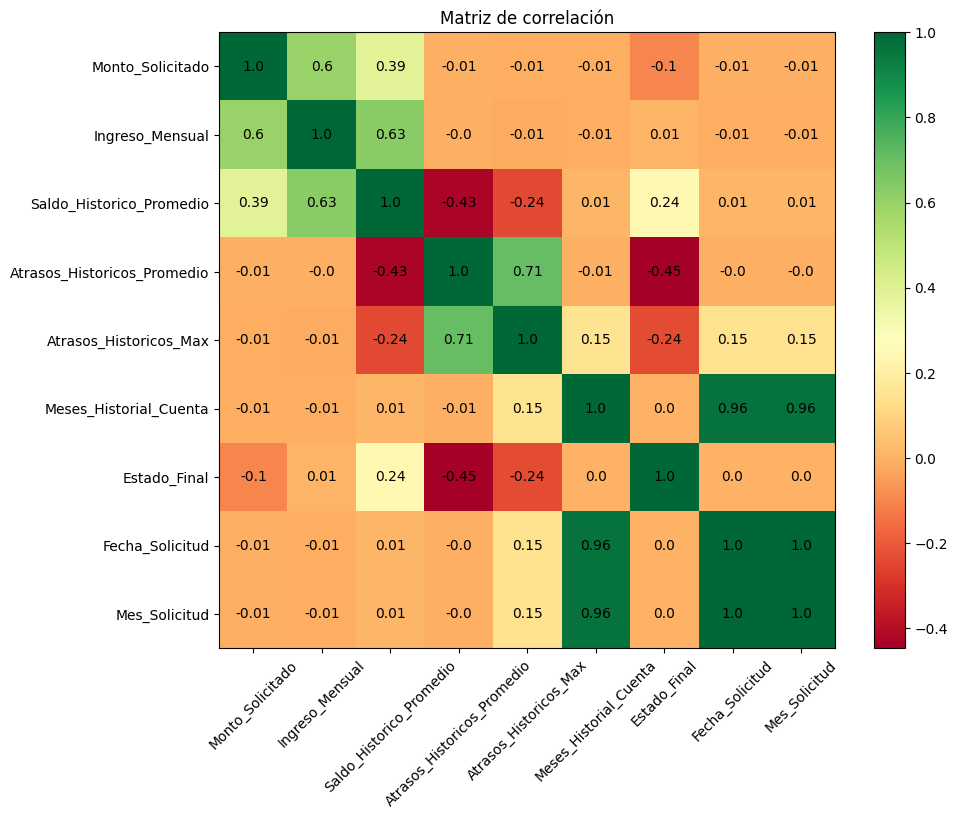

In [18]:
correlacion = datos_final_train[
    [
        "Monto_Solicitado",
        "Ingreso_Mensual",
        "Saldo_Historico_Promedio",
        "Atrasos_Historicos_Promedio",
        "Atrasos_Historicos_Max",
        "Meses_Historial_Cuenta",
        "Estado_Final",
        "Fecha_Solicitud",
        "Mes_Solicitud"
    ]
].corr()

plt.figure(figsize=(10, 8))

plt.imshow(correlacion, cmap="RdYlGn")

plt.colorbar()

plt.xticks(range(len(correlacion.columns)), correlacion.columns, rotation=45)

plt.yticks(range(len(correlacion.columns)), correlacion.columns)

# Mostrar el valor de correlación dentro de cada celda
for i in range(len(correlacion.columns)):
    for j in range(len(correlacion.columns)):
        plt.text(
            j, i,
            round(correlacion.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Matriz de correlación")
plt.show()

**Saldo histórico**: se encuentra una relación bastante marcada con Estado_Final (-0,45).\
**Atrasos históricos**: relación más débil (0,24), pero parece aportar información.\
**Monto solicitado**: parece tener cierta relación con el resultado y además tiene importancia económica.\
**Ingreso mensual**: por sí solo parecía diferenciar poco el estado, aunque está relacionado con Monto y Saldo.\
\
**Informacion extra analizada anteriormente**:\
**Tasa de interés**: diferencias minimas entre pagadores y defaults.\
**Motivo del préstamo**: las tasas de default son bastante similares entre categorías → no parece ser un predictor fuerte por sí solo.